# 02 - Churn Model & SHAP Explanations

Trains the **LightGBM** churn classifier on the engineered Telco snapshot and
explains its predictions with **SHAP** (beeswarm, bar and waterfall plots).

Paths use `os.path.join` so the notebook runs from any directory.

In [1]:
import json
import os
import sys

import pandas as pd


def find_project_root(start: str) -> str:
    current = os.path.abspath(start)
    while True:
        if os.path.isdir(os.path.join(current, "src")) and os.path.isdir(
            os.path.join(current, "config")
        ):
            return current
        parent = os.path.dirname(current)
        if parent == current:
            raise RuntimeError("Could not locate the project root (src/ + config/).")
        current = parent


PROJECT_ROOT = find_project_root(os.getcwd())
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

PROCESSED_DATA_DIR = os.path.join(PROJECT_ROOT, "data", "processed")
MODELS_DIR = os.path.join(PROJECT_ROOT, "models")
DIAGRAM_DIR = os.path.join(PROJECT_ROOT, "docs", "diagrams")
os.makedirs(MODELS_DIR, exist_ok=True)
print("PROJECT_ROOT:", PROJECT_ROOT)

PROJECT_ROOT: C:\Users\WELCOME\OneDrive\Desktop\nexvia\Customer Lifetime Value and Churn Intelligence System


## 1. Load the engineered snapshot

If notebook 01 has not been run yet, we build the snapshot on the fly from the raw
Kaggle file so this notebook is self-contained.

In [2]:
from src.data_pipeline.load_dataset import load_telco_data
from src.data_pipeline.feature_engineering import engineer_features

snapshot_path = os.path.join(PROCESSED_DATA_DIR, "telco_churn_processed.csv")

if os.path.exists(snapshot_path):
    df = pd.read_csv(snapshot_path)
    print("Loaded snapshot:", snapshot_path)
else:
    print("Snapshot missing - building from the raw Kaggle dataset.")
    df = engineer_features(load_telco_data())
    df.to_csv(snapshot_path, index=False)

print("Shape:", df.shape)
df[["tenure", "MonthlyCharges", "TotalCharges", "num_services", "Churn"]].head()

Loaded snapshot: C:\Users\WELCOME\OneDrive\Desktop\nexvia\Customer Lifetime Value and Churn Intelligence System\data\processed\telco_churn_processed.csv
Shape: (7043, 32)


,tenure,MonthlyCharges,TotalCharges,num_services,Churn
0,1,29.85,29.85,2,No
1,34,56.95,1889.50,4,No
2,2,53.85,108.15,4,Yes
3,45,42.30,1840.75,4,No
4,2,70.70,151.65,2,Yes


## 2. Train the LightGBM churn classifier

`ChurnClassifier.train_and_evaluate` performs an 80/20 stratified split, uses a
25% inner validation split for early stopping, and reports accuracy, precision,
recall, F1, ROC-AUC and PR-AUC on the untouched hold-out set.

In [3]:
from src.churn_model.churn_classifier import ChurnClassifier

classifier, metrics, X_test, y_test = ChurnClassifier.train_and_evaluate(df)

metrics_df = pd.Series(metrics, name="value").to_frame()
metrics_df["value"] = metrics_df["value"].round(4)
display(metrics_df)

C:\Users\WELCOME\AppData\Local\Programs\Python\Python310\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


,value
accuracy,0.7928
precision,0.6434
recall,0.4920
f1,0.5576
auc_roc,0.8406
auc_pr,0.6380


Confusion matrix [rows=true, cols=pred]:
[[933 102]
 [190 184]]

              precision    recall  f1-score   support

           0     0.8308    0.9014    0.8647      1035
           1     0.6434    0.4920    0.5576       374

    accuracy                         0.7928      1409
   macro avg     0.7371    0.6967    0.7111      1409
weighted avg     0.7811    0.7928    0.7832      1409



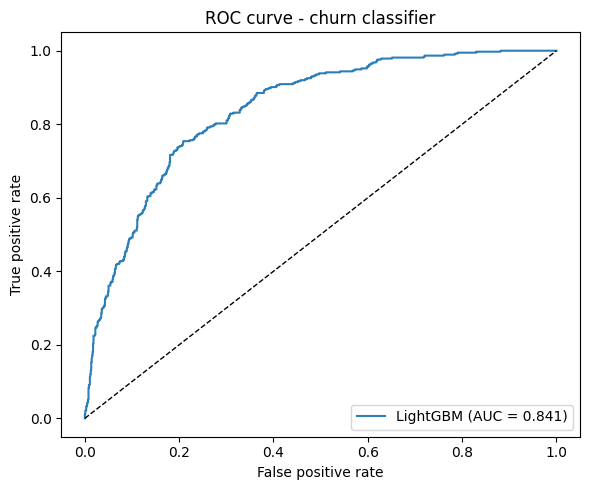

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt

y_pred = classifier.predict_class(X_test)
print("Confusion matrix [rows=true, cols=pred]:")
print(confusion_matrix(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, digits=4))

proba = classifier.predict(X_test)
fpr, tpr, _ = roc_curve(y_test, proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"LightGBM (AUC = {auc(fpr, tpr):.3f})", color="#2c7fb8")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve - churn classifier")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [5]:
# Persist the trained model and the metrics for the Streamlit app.
classifier.save_model(os.path.join(MODELS_DIR, "churn_lgbm_model.pkl"))
with open(os.path.join(MODELS_DIR, "churn_metrics.json"), "w", encoding="utf-8") as fh:
    json.dump(metrics, fh, indent=2)
print("Saved model + metrics to", MODELS_DIR)

Saved model + metrics to C:\Users\WELCOME\OneDrive\Desktop\nexvia\Customer Lifetime Value and Churn Intelligence System\models


## 3. Explain the model with SHAP

`ShapExplainer.generate_explanations` computes SHAP values for the test set and
writes a beeswarm summary, a bar chart and a single-customer waterfall plot.

In [6]:
from src.churn_model.shap_explainer import ShapExplainer

explainer = ShapExplainer.generate_explanations(classifier, X_test, save_dir=DIAGRAM_DIR)

importance = explainer.get_feature_importance_shap()
display(importance.head(15))
print("Top drivers:", explainer.get_top_features(10))

LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray


,feature,mean_abs_shap
0,Contract,0.931085
1,tenure,0.281410
2,avg_monthly_charge,0.254294
3,MonthlyCharges,0.230043
4,TotalCharges,0.078941
5,PaperlessBilling,0.074974
6,contract_risk,0.067598
7,StreamingMovies,0.067211
8,charge_increase,0.062087
9,PaymentMethod,0.057382


Top drivers: ['Contract', 'tenure', 'avg_monthly_charge', 'MonthlyCharges', 'TotalCharges', 'PaperlessBilling', 'contract_risk', 'StreamingMovies', 'charge_increase', 'PaymentMethod']


In [7]:
import matplotlib.image as mpimg

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, name in zip(axes, ["shap_summary.png", "shap_waterfall.png"]):
    img_path = os.path.join(DIAGRAM_DIR, name)
    if os.path.exists(img_path):
        ax.imshow(mpimg.imread(img_path))
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

FigureCanvasAgg is non-interactive, and thus cannot be shown


## 4. Score the full book of business

Attach a `churn_probability` column for every customer; downstream notebooks use it
for CLV, segmentation and ROI.

In [8]:
from src.data_pipeline.feature_engineering import prepare_model_data

X_all, _ = prepare_model_data(df)
df["churn_probability"] = classifier.predict(X_all)

scored_path = os.path.join(PROCESSED_DATA_DIR, "telco_churn_scored.csv")
df.to_csv(scored_path, index=False)

print("Scored rows:", len(df))
print("Mean churn probability: {:.3f}".format(df["churn_probability"].mean()))
print("Saved scored dataset:", scored_path)

Scored rows: 7043
Mean churn probability: 0.267
Saved scored dataset: C:\Users\WELCOME\OneDrive\Desktop\nexvia\Customer Lifetime Value and Churn Intelligence System\data\processed\telco_churn_scored.csv
